In [ ]:

from google.colab import files
from pathlib import Path

uploaded = files.upload()

zip_path = Path("/content") / next(iter(uploaded))

print("Uploaded file:", zip_path.name)
print("File size:", round(zip_path.stat().st_size / (1024 * 1024), 2), "MB")


Saving archive (1).zip to archive (1) (1).zip
Uploaded file: archive (1) (1).zip
File size: 28.27 MB


In [ ]:

import zipfile
from pathlib import Path

zip_path = Path("/content/archive (1) (1).zip")
extract_path = Path("/content/alzheimer_dataset")

extract_path.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("\nFolders and files found:")

for path in list(extract_path.rglob("*"))[:40]:
    if path.is_dir():
        print("FOLDER:", path.relative_to(extract_path))
    else:
        print("FILE:  ", path.relative_to(extract_path))


Dataset extracted successfully!

Folders and files found:
FOLDER: Alzheimer (Preprocessed Data)
FOLDER: Alzheimer (Preprocessed Data)/Mild_Demented
FOLDER: Alzheimer (Preprocessed Data)/Very_Mild_Demented
FOLDER: Alzheimer (Preprocessed Data)/Moderate_Demented
FOLDER: Alzheimer (Preprocessed Data)/Non_Demented
FILE:   Alzheimer (Preprocessed Data)/Mild_Demented/mild_427.jpg
FILE:   Alzheimer (Preprocessed Data)/Mild_Demented/mild_108.jpg
FILE:   Alzheimer (Preprocessed Data)/Mild_Demented/mild_37.jpg
FILE:   Alzheimer (Preprocessed Data)/Mild_Demented/mild_327.jpg
FILE:   Alzheimer (Preprocessed Data)/Mild_Demented/mild_352.jpg
FILE:   Alzheimer (Preprocessed Data)/Mild_Demented/mild_608.jpg
FILE:   Alzheimer (Preprocessed Data)/Mild_Demented/mild_517.jpg
FILE:   Alzheimer (Preprocessed Data)/Mild_Demented/mild_136.jpg
FILE:   Alzheimer (Preprocessed Data)/Mild_Demented/mild_302.jpg
FILE:   Alzheimer (Preprocessed Data)/Mild_Demented/mild_564.jpg
FILE:   Alzheimer (Preprocessed Data)/M

In [ ]:

from pathlib import Path
from PIL import Image

DATA_ROOT = Path(
    "/content/alzheimer_dataset/Alzheimer (Preprocessed Data)"
)

class_names = [
    "Mild_Demented",
    "Moderate_Demented",
    "Non_Demented",
    "Very_Mild_Demented"
]

total_images = 0

for class_name in class_names:
    class_path = DATA_ROOT / class_name

    image_paths = [
        p for p in class_path.iterdir()
        if p.is_file() and p.suffix.lower() in
        [".jpg", ".jpeg", ".png", ".bmp"]
    ]

    readable = 0
    unreadable = []

    for img_path in image_paths:
        try:
            with Image.open(img_path) as img:
                img.verify()
            readable += 1
        except Exception:
            unreadable.append(img_path.name)

    total_images += readable

    print(f"\nClass: {class_name}")
    print(f"Image files: {len(image_paths)}")
    print(f"Readable images: {readable}")
    print(f"Unreadable images: {len(unreadable)}")

    if unreadable:
        print("Examples of unreadable files:", unreadable[:5])

print("\n" + "=" * 40)
print("TOTAL READABLE IMAGES:", total_images)
print("=" * 40)



Class: Mild_Demented
Image files: 896
Readable images: 896
Unreadable images: 0

Class: Moderate_Demented
Image files: 64
Readable images: 64
Unreadable images: 0

Class: Non_Demented
Image files: 3200
Readable images: 3200
Unreadable images: 0

Class: Very_Mild_Demented
Image files: 2240
Readable images: 2240
Unreadable images: 0

TOTAL READABLE IMAGES: 6400


In [ ]:

!pip -q install ImageHash


In [ ]:

from pathlib import Path
from PIL import Image
import imagehash
from collections import defaultdict

DATA_ROOT = Path(
    "/content/alzheimer_dataset/Alzheimer (Preprocessed Data)"
)

class_names = [
    "Mild_Demented",
    "Moderate_Demented",
    "Non_Demented",
    "Very_Mild_Demented"
]

hash_groups = defaultdict(list)
total_checked = 0

for class_name in class_names:
    folder = DATA_ROOT / class_name

    for path in sorted(folder.iterdir()):
        if path.suffix.lower() not in [".jpg", ".jpeg", ".png", ".bmp"]:
            continue

        try:
            with Image.open(path) as img:
                phash = str(imagehash.phash(img.convert("L")))

            hash_groups[phash].append((class_name, path.name))
            total_checked += 1

        except Exception as e:
            print("Could not process:", path.name, e)

duplicate_groups = {
    h: items for h, items in hash_groups.items()
    if len(items) > 1
}

cross_class_groups = {
    h: items for h, items in duplicate_groups.items()
    if len(set(class_name for class_name, _ in items)) > 1
}

print("Images checked:", total_checked)
print("Unique perceptual hashes:", len(hash_groups))
print("Groups with identical perceptual hashes:", len(duplicate_groups))
print("Groups spanning multiple classes:", len(cross_class_groups))

print("\nExamples of groups spanning multiple classes:")
for h, items in list(cross_class_groups.items())[:10]:
    print("\nHash:", h)
    for class_name, filename in items:
        print(" ", class_name, "->", filename)


Images checked: 6400
Unique perceptual hashes: 6184
Groups with identical perceptual hashes: 207
Groups spanning multiple classes: 2

Examples of groups spanning multiple classes:

Hash: c2942f4b78f1343e
  Mild_Demented -> mild_359.jpg
  Very_Mild_Demented -> verymild_1237.jpg

Hash: c3b12f4a3cb5346a
  Non_Demented -> non_1616.jpg
  Very_Mild_Demented -> verymild_1051.jpg


In [ ]:

!pip -q install scikit-learn


In [ ]:

from pathlib import Path
from collections import defaultdict, Counter
from PIL import Image
import imagehash
import numpy as np

from sklearn.model_selection import StratifiedGroupKFold

DATA_ROOT = Path(
    "/content/alzheimer_dataset/Alzheimer (Preprocessed Data)"
)

class_names = [
    "Mild_Demented",
    "Moderate_Demented",
    "Non_Demented",
    "Very_Mild_Demented"
]

paths = []
labels = []
groups = []

for label, class_name in enumerate(class_names):
    for path in sorted((DATA_ROOT / class_name).iterdir()):
        if path.suffix.lower() not in [".jpg", ".jpeg", ".png", ".bmp"]:
            continue

        with Image.open(path) as img:
            phash = str(imagehash.phash(img.convert("L")))

        paths.append(str(path))
        labels.append(label)
        groups.append(phash)

paths = np.array(paths)
labels = np.array(labels)
groups = np.array(groups)

print("Total images:", len(paths))
print("Classes:", dict(Counter(
    class_names[label] for label in labels
)))

# First split: 15% test, keeping matching hashes together.
split1 = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

trainval_idx, test_idx = next(
    split1.split(paths, labels, groups)
)

# Split the remaining 85% into 70% train and 15% validation.
# 15/85 = approximately 17.65% of the remaining data.
split2 = StratifiedGroupKFold(
    n_splits=6, shuffle=True, random_state=43
)

trainval_paths = paths[trainval_idx]
trainval_labels = labels[trainval_idx]
trainval_groups = groups[trainval_idx]

train_rel_idx, val_rel_idx = next(
    split2.split(trainval_paths, trainval_labels, trainval_groups)
)

train_idx = trainval_idx[train_rel_idx]
val_idx = trainval_idx[val_rel_idx]

# Verify no identical perceptual hash crosses partitions.
train_hashes = set(groups[train_idx])
val_hashes = set(groups[val_idx])
test_hashes = set(groups[test_idx])

print("\nSplit sizes:")
for name, idx in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    print(f"\n{name}: {len(idx)} images")
    counts = Counter(class_names[labels[i]] for i in idx)
    for class_name in class_names:
        print(f"  {class_name}: {counts.get(class_name, 0)}")

print("\nMatching-hash overlap:")
print("Train vs Validation:", len(train_hashes & val_hashes))
print("Train vs Test:", len(train_hashes & test_hashes))
print("Validation vs Test:", len(val_hashes & test_hashes))

print("\nSplit completed.")


Total images: 6400
Classes: {'Mild_Demented': 896, 'Moderate_Demented': 64, 'Non_Demented': 3200, 'Very_Mild_Demented': 2240}

Split sizes:

Train: 4260 images
  Mild_Demented: 589
  Moderate_Demented: 45
  Non_Demented: 2140
  Very_Mild_Demented: 1486

Validation: 860 images
  Mild_Demented: 138
  Moderate_Demented: 8
  Non_Demented: 425
  Very_Mild_Demented: 289

Test: 1280 images
  Mild_Demented: 169
  Moderate_Demented: 11
  Non_Demented: 635
  Very_Mild_Demented: 465

Matching-hash overlap:
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0

Split completed.


In [ ]:

import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Go to Runtime > Change runtime type > T4 GPU.")


PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
GPU available: True
GPU name: Tesla T4


In [ ]:

!pip -q install timm imbalanced-learn


In [ ]:

import torch
import timm
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=True,
    num_classes=0
)

model = model.to(device)
model.eval()

print("Device:", device)
print("Model: Swin Transformer-Tiny")
print("Model parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Feature dimension:", model.num_features)
print("Pretrained weights loaded successfully!")


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Device: cuda
Model: Swin Transformer-Tiny
Model parameters: 27,519,354
Feature dimension: 768
Pretrained weights loaded successfully!


In [ ]:

from torchvision import transforms
from PIL import Image

IMG_SIZE = 224

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Test preprocessing on one MRI image
sample_path = next(DATA_ROOT.joinpath("Mild_Demented").glob("*.jpg"))

with Image.open(sample_path) as img:
    sample_tensor = transform(img.convert("RGB"))

print("Sample image:", sample_path.name)
print("Processed tensor shape:", sample_tensor.shape)
print("Tensor data type:", sample_tensor.dtype)
print("Device for model:", device)


Sample image: mild_427.jpg
Processed tensor shape: torch.Size([3, 224, 224])
Tensor data type: torch.float32
Device for model: cuda


In [ ]:

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from tqdm.auto import tqdm

class MRIDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as img:
            image = self.transform(img.convert("RGB"))

        return image, int(self.labels[idx])


def extract_features(indices, split_name, batch_size=32):
    dataset = MRIDataset(
        paths[indices],
        labels[indices],
        transform
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    feature_batches = []
    label_batches = []

    model.eval()

    with torch.inference_mode():
        for images, batch_labels in tqdm(loader, desc=split_name):
            images = images.to(device, non_blocking=True)

            features = model(images)

            feature_batches.append(features.cpu().numpy())
            label_batches.append(batch_labels.numpy())

    X = np.concatenate(feature_batches, axis=0)
    y = np.concatenate(label_batches, axis=0)

    print(f"\n{split_name} features: {X.shape}")
    print(f"{split_name} labels: {y.shape}")

    return X, y


X_train, y_train = extract_features(train_idx, "Training")
X_val, y_val = extract_features(val_idx, "Validation")
X_test, y_test = extract_features(test_idx, "Testing")

print("\nFeature extraction completed.")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


Training:   0%|          | 0/134 [00:00<?, ?it/s]


Training features: (4260, 768)
Training labels: (4260,)


Validation:   0%|          | 0/27 [00:00<?, ?it/s]


Validation features: (860, 768)
Validation labels: (860,)


Testing:   0%|          | 0/40 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c951b351f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c951b351f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Testing features: (1280, 768)
Testing labels: (1280,)

Feature extraction completed.
Training: (4260, 768)
Validation: (860, 768)
Testing: (1280, 768)


In [ ]:

from collections import Counter
import numpy as np

print("Training class counts before SMOTE:")
for label, count in sorted(Counter(y_train).items()):
    print(f"{class_names[label]}: {count}")

print("\nValidation shape:", X_val.shape)
print("Test shape:", X_test.shape)

assert X_train.shape == (4260, 768)
assert X_val.shape == (860, 768)
assert X_test.shape == (1280, 768)

print("\nFeature arrays verified successfully.")


Training class counts before SMOTE:
Mild_Demented: 589
Moderate_Demented: 45
Non_Demented: 2140
Very_Mild_Demented: 1486

Validation shape: (860, 768)
Test shape: (1280, 768)

Feature arrays verified successfully.


In [ ]:

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report
from imblearn.over_sampling import SMOTE
from collections import Counter
import numpy as np

# 1. Scale using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

# 2. Apply SMOTE to training features only
smote = SMOTE(random_state=42, k_neighbors=5)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled, y_train
)

print("\nTraining counts after SMOTE:")
for label, count in sorted(Counter(y_train_balanced).items()):
    print(f"{class_names[label]}: {count}")

# 3. Compare SVM hyperparameters using validation macro-F1
c_values = [1, 10]
gamma_values = ["scale", 0.001]

best_model = None
best_macro_f1 = -1
best_params = None

for c in c_values:
    for gamma in gamma_values:
        print(f"\nTraining SVM: C={c}, gamma={gamma}")

        svm = SVC(
            kernel="rbf",
            C=c,
            gamma=gamma,
            class_weight=None
        )

        svm.fit(X_train_balanced, y_train_balanced)

        val_predictions = svm.predict(X_val_scaled)
        val_macro_f1 = f1_score(
            y_val, val_predictions, average="macro"
        )
        val_accuracy = accuracy_score(y_val, val_predictions)

        print(f"Validation accuracy: {val_accuracy * 100:.2f}%")
        print(f"Validation macro-F1: {val_macro_f1 * 100:.2f}%")

        if val_macro_f1 > best_macro_f1:
            best_macro_f1 = val_macro_f1
            best_model = svm
            best_params = {"C": c, "gamma": gamma}

print("\n" + "=" * 45)
print("BEST PARAMETERS:", best_params)
print(f"Best validation macro-F1: {best_macro_f1 * 100:.2f}%")
print("=" * 45)

# 4. Evaluate the selected model on the test set
# Test data is not used for model selection.
test_predictions = best_model.predict(X_test_scaled)

test_accuracy = accuracy_score(y_test, test_predictions)
test_macro_f1 = f1_score(
    y_test, test_predictions, average="macro"
)

print(f"\nTEST ACCURACY: {test_accuracy * 100:.2f}%")
print(f"TEST MACRO-F1: {test_macro_f1 * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0,
    digits=4
))


Feature scaling completed.

Training counts after SMOTE:
Mild_Demented: 2140
Moderate_Demented: 2140
Non_Demented: 2140
Very_Mild_Demented: 2140

Training SVM: C=1, gamma=scale
Validation accuracy: 86.40%
Validation macro-F1: 89.79%

Training SVM: C=1, gamma=0.001
Validation accuracy: 82.91%
Validation macro-F1: 86.93%

Training SVM: C=10, gamma=scale
Validation accuracy: 91.16%
Validation macro-F1: 92.76%

Training SVM: C=10, gamma=0.001
Validation accuracy: 90.81%
Validation macro-F1: 92.72%

BEST PARAMETERS: {'C': 10, 'gamma': 'scale'}
Best validation macro-F1: 92.76%

TEST ACCURACY: 93.12%
TEST MACRO-F1: 94.84%

Classification report:
                    precision    recall  f1-score   support

     Mild_Demented     0.9571    0.9231    0.9398       169
 Moderate_Demented     1.0000    1.0000    1.0000        11
      Non_Demented     0.9348    0.9480    0.9414       635
Very_Mild_Demented     0.9156    0.9097    0.9126       465

          accuracy                         0.9313  

Confusion matrix (rows = actual, columns = predicted):
[[156   0   4   9]
 [  0  11   0   0]
 [  3   0 602  30]
 [  4   0  38 423]]


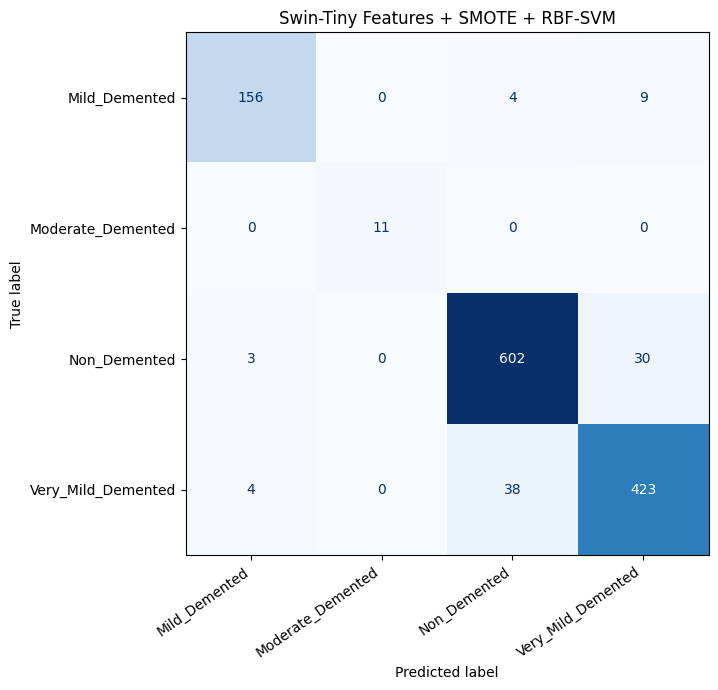

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=range(len(class_names))
)

print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Swin-Tiny Features + SMOTE + RBF-SVM")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


In [ ]:

from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [ ]:

import os
import joblib
import numpy as np

SAVE_DIR = "/content/swin_svm_results"
os.makedirs(SAVE_DIR, exist_ok=True)

# Save the trained SVM and feature scaler
joblib.dump(best_model, f"{SAVE_DIR}/best_rbf_svm.joblib")
joblib.dump(scaler, f"{SAVE_DIR}/feature_scaler.joblib")

# Save test predictions and actual labels
np.savez(
    f"{SAVE_DIR}/test_predictions.npz",
    y_test=y_test,
    test_predictions=test_predictions
)

print("Model and results saved successfully!")
print("Location:", SAVE_DIR)
print("Files:", os.listdir(SAVE_DIR))


Model and results saved successfully!
Location: /content/swin_svm_results
Files: ['best_rbf_svm.joblib', 'test_predictions.npz', 'feature_scaler.joblib']


In [ ]:

import torch
import os

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Training features available:", "X_train" in globals())
print("Validation features available:", "X_val" in globals())
print("Test features available:", "X_test" in globals())
print("Best SVM available:", "best_model" in globals())


GPU available: True
GPU: Tesla T4
Training features available: True
Validation features available: True
Test features available: True
Best SVM available: True


In [ ]:
import os

paths_to_check = [
    "/content/swin_svm_results/best_rbf_svm.joblib",
    "/content/swin_svm_results/feature_scaler.joblib",
    "/content/swin_svm_results/test_predictions.npz",
    "/content/drive/MyDrive/Alzheimer_Swin_Project/swin_svm_results/best_rbf_svm.joblib",
    "/content/drive/MyDrive/Alzheimer_Swin_Project/swin_svm_results/feature_scaler.joblib",
    "/content/drive/MyDrive/Alzheimer_Swin_Project/swin_svm_results/test_predictions.npz",
]

for path in paths_to_check:
    print(
        "FOUND " if os.path.isfile(path) else "NOT FOUND ",
        path
    )

FOUND  /content/swin_svm_results/best_rbf_svm.joblib
FOUND  /content/swin_svm_results/feature_scaler.joblib
FOUND  /content/swin_svm_results/test_predictions.npz
NOT FOUND  /content/drive/MyDrive/Alzheimer_Swin_Project/swin_svm_results/best_rbf_svm.joblib
NOT FOUND  /content/drive/MyDrive/Alzheimer_Swin_Project/swin_svm_results/feature_scaler.joblib
NOT FOUND  /content/drive/MyDrive/Alzheimer_Swin_Project/swin_svm_results/test_predictions.npz


In [ ]:
print("Training variables available:",
      "X_train_smote" in globals(),
      "X_val" in globals(),
      "y_val" in globals())

print("GPU available:", torch.cuda.is_available())

Training variables available: True True True
GPU available: True


In [ ]:
print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Training labels:", len(y_train))
print("Validation labels:", len(y_val))
print("SMOTE data available:", "X_train_smote" in globals())

Training features: (4260, 768)
Validation features: (860, 768)
Training labels: 4260
Validation labels: 860
SMOTE data available: True


In [ ]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import time

# Reuse existing SMOTE data and test only 4 configurations
configs = [
    {"C": 3,  "gamma": "scale"},
    {"C": 10, "gamma": "scale"},
    {"C": 30, "gamma": "scale"},
    {"C": 10, "gamma": 0.001},
]

results = []
best_f1 = -1
best_model_tuned = None

for cfg in configs:
    start = time.time()

    model = SVC(
        kernel="rbf",
        C=cfg["C"],
        gamma=cfg["gamma"]
    )
    model.fit(X_train_smote, y_train_smote)
    pred = model.predict(X_val)

    acc = accuracy_score(y_val, pred)
    f1 = f1_score(
        y_val, pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "C": cfg["C"],
        "gamma": cfg["gamma"],
        "val_accuracy_pct": round(acc * 100, 2),
        "val_macro_f1_pct": round(f1 * 100, 2)
    })

    print(
        f"{cfg} | Accuracy: {acc*100:.2f}%"
        f" | Macro-F1: {f1*100:.2f}%"
        f" | Time: {time.time()-start:.1f}s",
        flush=True
    )

    if f1 > best_f1:
        best_f1 = f1
        best_model_tuned = model
        best_params_tuned = cfg

display(pd.DataFrame(results).sort_values(
    "val_macro_f1_pct", ascending=False
))

print("Best validation parameters:", best_params_tuned)
print(f"Best validation macro-F1: {best_f1*100:.2f}%")



{'C': 3, 'gamma': 'scale'} | Accuracy: 73.26% | Macro-F1: 77.15% | Time: 25.5s
{'C': 10, 'gamma': 'scale'} | Accuracy: 81.40% | Macro-F1: 85.37% | Time: 13.7s
{'C': 30, 'gamma': 'scale'} | Accuracy: 86.16% | Macro-F1: 89.35% | Time: 12.2s
{'C': 10, 'gamma': 0.001} | Accuracy: 70.47% | Macro-F1: 74.76% | Time: 17.3s


,C,gamma,val_accuracy_pct,val_macro_f1_pct
2,30,scale,86.16,89.35
1,10,scale,81.40,85.37
0,3,scale,73.26,77.15
3,10,0.001,70.47,74.76


Best validation parameters: {'C': 30, 'gamma': 'scale'}
Best validation macro-F1: 89.35%


In [ ]:
import os

for path in [
    "/content/swin_svm_results/best_rbf_svm.joblib",
    "/content/swin_svm_results/feature_scaler.joblib"
]:
    print(
        "FOUND" if os.path.isfile(path) else "MISSING",
        path
    )

FOUND /content/swin_svm_results/best_rbf_svm.joblib
FOUND /content/swin_svm_results/feature_scaler.joblib


In [ ]:
import joblib
import os

MODEL_PATH = "/content/swin_svm_results/best_rbf_svm.joblib"
SCALER_PATH = "/content/swin_svm_results/feature_scaler.joblib"

original_svm = joblib.load(MODEL_PATH)
original_scaler = joblib.load(SCALER_PATH)

print("Original SVM loaded:", type(original_svm).__name__)
print("Original scaler loaded:", type(original_scaler).__name__)
print("SVM parameters:", original_svm.get_params())
print("Scaler mean shape:", original_scaler.mean_.shape)
print("Scaler feature count:", original_scaler.n_features_in_)

Original SVM loaded: SVC
Original scaler loaded: StandardScaler
SVM parameters: {'C': 10, 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'probability': False, 'random_state': None, 'shrinking': True, 'tol': 0.001, 'verbose': False}
Scaler mean shape: (768,)
Scaler feature count: 768


In [ ]:

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
from imblearn.over_sampling import SMOTE
import pandas as pd

# Fit scaler on original training features only
scaler_compare = StandardScaler()
Xtr = scaler_compare.fit_transform(X_train)
Xva = scaler_compare.transform(X_val)

# SMOTE applied only to training data
Xtr_smote, ytr_smote = SMOTE(
    random_state=42
).fit_resample(Xtr, y_train)

experiments = [
    ("SMOTE + RBF-SVM", Xtr_smote, ytr_smote, None),
    ("Class-weighted RBF-SVM", Xtr, y_train, "balanced"),
]

results = []

for name, Xfit, yfit, weights in experiments:
    model = SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        class_weight=weights
    )
    model.fit(Xfit, yfit)
    pred = model.predict(Xva)

    results.append({
        "Experiment": name,
        "Validation accuracy (%)": round(
            accuracy_score(y_val, pred) * 100, 2
        ),
        "Validation macro-F1 (%)": round(
            f1_score(
                y_val, pred,
                average="macro",
                zero_division=0
            ) * 100, 2
        )
    })

display(pd.DataFrame(results))


,Experiment,Validation accuracy (%),Validation macro-F1 (%)
0,SMOTE + RBF-SVM,91.16,92.76
1,Class-weighted RBF-SVM,90.81,92.68


In [ ]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import time

results_tuned = []
best_f1_tuned = -1
best_svm_tuned = None

for C_value in [10, 30, 100]:
    start = time.time()

    model = SVC(
        kernel="rbf",
        C=C_value,
        gamma="scale"
    )
    model.fit(Xtr_smote, ytr_smote)
    pred = model.predict(Xva)

    acc = accuracy_score(y_val, pred)
    macro_f1 = f1_score(
        y_val, pred,
        average="macro",
        zero_division=0
    )

    results_tuned.append({
        "C": C_value,
        "Validation accuracy (%)": round(acc * 100, 2),
        "Validation macro-F1 (%)": round(macro_f1 * 100, 2)
    })

    print(
        f"C={C_value} | Accuracy={acc*100:.2f}% "
        f"| Macro-F1={macro_f1*100:.2f}% "
        f"| Time={time.time()-start:.1f}s",
        flush=True
    )

    if macro_f1 > best_f1_tuned:
        best_f1_tuned = macro_f1
        best_svm_tuned = model
        best_C_tuned = C_value

display(pd.DataFrame(results_tuned))
print("Best C:", best_C_tuned)
print("Best validation macro-F1:", round(best_f1_tuned*100, 2))


C=10 | Accuracy=91.16% | Macro-F1=92.76% | Time=21.9s
C=30 | Accuracy=91.16% | Macro-F1=92.76% | Time=14.7s
C=100 | Accuracy=91.16% | Macro-F1=92.76% | Time=15.6s


,C,Validation accuracy (%),Validation macro-F1 (%)
0,10,91.16,92.76
1,30,91.16,92.76
2,100,91.16,92.76


Best C: 30
Best validation macro-F1: 92.76


In [ ]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import time

gamma_results = []

for gamma_value in ["scale", 0.0001, 0.01]:
    start = time.time()

    model = SVC(
        kernel="rbf",
        C=10,
        gamma=gamma_value
    )

    model.fit(Xtr_smote, ytr_smote)
    pred = model.predict(Xva)

    acc = accuracy_score(y_val, pred)
    macro_f1 = f1_score(
        y_val, pred,
        average="macro",
        zero_division=0
    )

    gamma_results.append({
        "gamma": gamma_value,
        "Validation accuracy (%)": round(acc * 100, 2),
        "Validation macro-F1 (%)": round(macro_f1 * 100, 2)
    })

    print(
        f"gamma={gamma_value} | "
        f"Accuracy={acc*100:.2f}% | "
        f"Macro-F1={macro_f1*100:.2f}% | "
        f"Time={time.time()-start:.1f}s",
        flush=True
    )

display(pd.DataFrame(gamma_results))


gamma=scale | Accuracy=91.16% | Macro-F1=92.76% | Time=22.9s
gamma=0.0001 | Accuracy=72.09% | Macro-F1=76.23% | Time=18.0s
gamma=0.01 | Accuracy=67.56% | Macro-F1=46.73% | Time=37.3s


,gamma,Validation accuracy (%),Validation macro-F1 (%)
0,scale,91.16,92.76
1,0.0001,72.09,76.23
2,0.01,67.56,46.73


In [ ]:

from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
from imblearn.over_sampling import SMOTE
import pandas as pd

results_pca = []

for n in [128, 256, 384]:
    pca = PCA(n_components=n, random_state=42)
    Xtr_pca = pca.fit_transform(Xtr)
    Xva_pca = pca.transform(Xva)

    Xsm, ysm = SMOTE(random_state=42).fit_resample(
        Xtr_pca, y_train
    )

    model = SVC(C=10, kernel="rbf", gamma="scale")
    model.fit(Xsm, ysm)
    pred = model.predict(Xva_pca)

    acc = accuracy_score(y_val, pred)
    f1 = f1_score(
        y_val, pred, average="macro", zero_division=0
    )

    results_pca.append({
        "PCA components": n,
        "Explained variance (%)": round(
            pca.explained_variance_ratio_.sum() * 100, 2
        ),
        "Validation accuracy (%)": round(acc * 100, 2),
        "Validation macro-F1 (%)": round(f1 * 100, 2)
    })

    print(f"PCA {n}: Accuracy={acc*100:.2f}%, Macro-F1={f1*100:.2f}%")

display(pd.DataFrame(results_pca))


PCA 128: Accuracy=89.53%, Macro-F1=91.75%
PCA 256: Accuracy=89.42%, Macro-F1=91.63%
PCA 384: Accuracy=90.70%, Macro-F1=92.41%


,PCA components,Explained variance (%),Validation accuracy (%),Validation macro-F1 (%)
0,128,95.040001,89.53,91.75
1,256,98.250000,89.42,91.63
2,384,99.300003,90.70,92.41


In [ ]:
from google.colab import drive, files
import shutil
from pathlib import Path

# Mount Google Drive
drive.mount('/content/drive')

# Find your existing notebook backup if already stored in Drive
notebook_dir = Path('/content/drive/MyDrive')

print("Drive connected.")
print("Your notebook is saved in Google Drive if you previously saved it there.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive connected.
Your notebook is saved in Google Drive if you previously saved it there.


In [ ]:
from pathlib import Path

paths = [
    "/content/swin_svm_results/best_rbf_svm.joblib",
    "/content/swin_svm_results/feature_scaler.joblib",
    "/content/swin_svm_results/test_predictions.npz",
    "/content/drive/MyDrive/Alzheimer_Swin_Project/finetune_checkpoints/best_swin_tiny.pth"
]

for p in paths:
    print(("FOUND  " if Path(p).exists() else "MISSING"), p)

FOUND   /content/swin_svm_results/best_rbf_svm.joblib
FOUND   /content/swin_svm_results/feature_scaler.joblib
FOUND   /content/swin_svm_results/test_predictions.npz
FOUND   /content/drive/MyDrive/Alzheimer_Swin_Project/finetune_checkpoints/best_swin_tiny.pth


In [ ]:
from google.colab import files
from pathlib import Path
import shutil

folder = Path("/content/drive/MyDrive/Alzheimer_Swin_Project/experiment1_backup")

for name in [
    "best_rbf_svm.joblib",
    "feature_scaler.joblib",
    "test_predictions.npz"
]:
    path = folder / name
    if path.exists():
        files.download(str(path))
    else:
        print("Missing file:", name)

Missing file: best_rbf_svm.joblib
Missing file: feature_scaler.joblib
Missing file: test_predictions.npz


In [ ]:

from pathlib import Path
import shutil

source = Path("/content/swin_svm_results")
backup = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/experiment1_backup"
)
backup.mkdir(parents=True, exist_ok=True)

names = [
    "best_rbf_svm.joblib",
    "feature_scaler.joblib",
    "test_predictions.npz"
]

for name in names:
    src = source / name
    dst = backup / name

    if src.exists():
        shutil.copy2(src, dst)
        print("BACKED UP:", name)
    else:
        print("NOT FOUND IN CURRENT SESSION:", name)

print("\nDrive backup folder:", backup)


BACKED UP: best_rbf_svm.joblib
BACKED UP: feature_scaler.joblib
BACKED UP: test_predictions.npz

Drive backup folder: /content/drive/MyDrive/Alzheimer_Swin_Project/experiment1_backup


In [ ]:
from google.colab import files
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/experiment1_backup"
)

for name in [
    "best_rbf_svm.joblib",
    "feature_scaler.joblib",
    "test_predictions.npz"
]:
    files.download(str(folder / name))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
required_vars = [
    "X_train", "X_val", "X_test",
    "y_train", "y_val", "y_test",
    "class_names"
]

for name in required_vars:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

print("\nExisting Experiment 1 files:")
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/experiment1_backup"
)

for name in [
    "best_rbf_svm.joblib",
    "feature_scaler.joblib",
    "test_predictions.npz"
]:
    print(f"{name}: {'Available' if (folder / name).exists() else 'Missing'}")

X_train: Available
X_val: Available
X_test: Available
y_train: Available
y_val: Available
y_test: Available
class_names: Available

Existing Experiment 1 files:
best_rbf_svm.joblib: Available
feature_scaler.joblib: Available
test_predictions.npz: Available


In [ ]:
model = timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=True,
    num_classes=0
)

In [ ]:

import numpy as np

for name in ["X_train", "X_val", "X_test",
             "y_train", "y_val", "y_test"]:
    arr = globals().get(name)
    if arr is None:
        print(f"{name}: MISSING")
    else:
        print(f"{name}: shape={np.asarray(arr).shape}")

print("\nClasses:", class_names)


X_train: shape=(4260, 768)
X_val: shape=(860, 768)
X_test: shape=(1280, 768)
y_train: shape=(4260,)
y_val: shape=(860,)
y_test: shape=(1280,)

Classes: ['Mild_Demented', 'Moderate_Demented', 'Non_Demented', 'Very_Mild_Demented']


In [ ]:

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
from imblearn.over_sampling import SMOTE
from pathlib import Path
import joblib

# Scale using training data only
scaler_new = StandardScaler()
Xtr = scaler_new.fit_transform(X_train)
Xva = scaler_new.transform(X_val)

# Balance training data only
Xtr_bal, ytr_bal = SMOTE(random_state=42).fit_resample(
    Xtr, y_train
)

results = []

for C in [10, 30]:
    clf = SVC(C=C, kernel="rbf", gamma="scale")
    clf.fit(Xtr_bal, ytr_bal)
    pred = clf.predict(Xva)

    acc = accuracy_score(y_val, pred)
    mf1 = f1_score(y_val, pred, average="macro")
    results.append((mf1, acc, C, clf))

    print(
        f"C={C} | Validation accuracy={acc*100:.2f}% "
        f"| Macro-F1={mf1*100:.2f}%"
    )

best = max(results, key=lambda x: x[0])

# Save separately; preserve Experiment 1
out = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/experiment2_validation"
)
out.mkdir(parents=True, exist_ok=True)

joblib.dump(best[3], out / "svm_model.joblib")
joblib.dump(scaler_new, out / "scaler.joblib")

print("\nBest C:", best[2])
print("Best validation macro-F1:", round(best[0] * 100, 2), "%")
print("Saved to:", out)


C=10 | Validation accuracy=91.16% | Macro-F1=92.76%
C=30 | Validation accuracy=91.16% | Macro-F1=92.76%

Best C: 30
Best validation macro-F1: 92.76 %
Saved to: /content/drive/MyDrive/Alzheimer_Swin_Project/experiment2_validation


In [ ]:

import numpy as np
import joblib
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, confusion_matrix
)

out = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/experiment2_validation"
)

model = joblib.load(out / "svm_model.joblib")
scaler = joblib.load(out / "scaler.joblib")

Xte = scaler.transform(X_test)
pred_test = model.predict(Xte)

print("Test accuracy:", round(accuracy_score(y_test, pred_test) * 100, 2), "%")
print("Test macro-F1:", round(f1_score(y_test, pred_test, average="macro") * 100, 2), "%")
print("\nClassification report:")
print(classification_report(
    y_test, pred_test,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(y_test, pred_test))

np.savez(
    out / "test_results.npz",
    y_true=y_test,
    y_pred=pred_test,
    class_names=np.array(class_names)
)
print("\nResults saved to:", out)


Test accuracy: 93.12 %
Test macro-F1: 94.84 %

Classification report:
                    precision    recall  f1-score   support

     Mild_Demented       0.96      0.92      0.94       169
 Moderate_Demented       1.00      1.00      1.00        11
      Non_Demented       0.93      0.95      0.94       635
Very_Mild_Demented       0.92      0.91      0.91       465

          accuracy                           0.93      1280
         macro avg       0.95      0.95      0.95      1280
      weighted avg       0.93      0.93      0.93      1280

Confusion matrix:
[[156   0   4   9]
 [  0  11   0   0]
 [  3   0 602  30]
 [  4   0  38 423]]

Results saved to: /content/drive/MyDrive/Alzheimer_Swin_Project/experiment2_validation


In [ ]:

print("Checking current Colab variables...")

for name in [
    "model", "timm", "device",
    "train_idx", "val_idx", "test_idx",
    "paths", "image_paths", "all_paths"
]:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

import os
print("\nDataset root exists:",
      os.path.exists("/content/alzheimer_dataset"))

print("Original model backup exists:",
      os.path.exists(
          "/content/drive/MyDrive/Alzheimer_Swin_Project/experiment1_backup/best_rbf_svm.joblib"
      ))


Checking current Colab variables...
model: Available
timm: Available
device: Available
train_idx: Available
val_idx: Available
test_idx: Available
paths: Available
image_paths: Available
all_paths: Missing

Dataset root exists: True
Original model backup exists: True


In [ ]:

import timm
import torch

print("Device:", device)
print("Model type:", type(model).__name__)

# Inspect the Swin-Tiny architecture
swin_inspect = timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=False,
    num_classes=0
)

print("\nSwin-Tiny feature stages:")
if hasattr(swin_inspect, "layers"):
    for i, layer in enumerate(swin_inspect.layers):
        print(f"Stage {i + 1}: {type(layer).__name__}")
else:
    print("Model uses a different stage structure; inspect named modules:")
    for name, module in swin_inspect.named_children():
        print(name, type(module).__name__)


Device: cuda
Model type: SVC

Swin-Tiny feature stages:
Stage 1: SwinTransformerStage
Stage 2: SwinTransformerStage
Stage 3: SwinTransformerStage
Stage 4: SwinTransformerStage


In [ ]:

import torch
import timm
import numpy as np
from pathlib import Path
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# Keep your existing dataset and class ordering
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained Swin-Tiny with intermediate feature outputs
fusion_model = timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=True,
    features_only=True,
    out_indices=(0, 1, 2, 3)
).to(device).eval()

print("Feature channels:", fusion_model.feature_info.channels())
print("Device:", device)


Feature channels: [96, 192, 384, 768]
Device: cuda


In [ ]:

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from tqdm.auto import tqdm
from pathlib import Path

# Standard Swin-Tiny input preprocessing
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class MRIPathDataset(Dataset):
    def __init__(self, paths, indices):
        self.paths = [str(paths[i]) for i in indices]
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as im:
            image = transform(im.convert("RGB"))
        return image

def extract_stage_features(indices, batch_size=32):
    loader = DataLoader(
        MRIPathDataset(paths, indices),
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )
    collected = [[] for _ in range(4)]

    with torch.inference_mode():
        for images in tqdm(loader):
            outputs = fusion_model(images.to(device, non_blocking=True))
            for stage, feature in enumerate(outputs):
                # timm feature maps: B, H, W, C or B, C, H, W
                if feature.ndim == 4 and feature.shape[-1] in [96, 192, 384, 768]:
                    feature = feature.mean(dim=(1, 2))
                elif feature.ndim == 4:
                    feature = feature.mean(dim=(2, 3))
                collected[stage].append(feature.float().cpu().numpy())

    return [
        np.concatenate(parts, axis=0)
        for parts in collected
    ]

F_train = extract_stage_features(train_idx)
F_val   = extract_stage_features(val_idx)
F_test  = extract_stage_features(test_idx)

print("\nStage shapes:")
for i in range(4):
    print(
        f"Stage {i+1}:",
        F_train[i].shape,
        F_val[i].shape,
        F_test[i].shape
    )

save_dir = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/multistage_features"
)
save_dir.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    save_dir / "swin_multistage_features.npz",
    **{f"train_s{i+1}": F_train[i] for i in range(4)},
    **{f"val_s{i+1}": F_val[i] for i in range(4)},
    **{f"test_s{i+1}": F_test[i] for i in range(4)}
)

print("\nFeatures saved to:", save_dir)


IndexError: list index out of range

In [ ]:
print("Length of paths:", len(paths))
print("Length of image_paths:", len(image_paths))

for name in ["train_idx", "val_idx", "test_idx"]:
    idx = globals()[name]
    print(
        name,
        "| count:", len(idx),
        "| minimum:", min(idx),
        "| maximum:", max(idx)
    )

Length of paths: 4
Length of image_paths: 2240
train_idx | count: 4260 | minimum: 0 | maximum: 6399
val_idx | count: 860 | minimum: 6 | maximum: 6389
test_idx | count: 1280 | minimum: 7 | maximum: 6396


In [ ]:
candidates = {
    "paths": paths,
    "image_paths": image_paths
}

for name, candidate in candidates.items():
    try:
        n = len(candidate)
        valid = all(
            min(globals()[idx_name]) >= 0
            and max(globals()[idx_name]) < n
            for idx_name in ["train_idx", "val_idx", "test_idx"]
        )
        print(name, "| length:", n, "| indices valid:", valid)
    except Exception as e:
        print(name, "| check failed:", e)

paths | length: 4 | indices valid: False
image_paths | length: 2240 | indices valid: False


In [ ]:

from pathlib import Path

DATA_ROOT = Path("/content/alzheimer_dataset")

class_names = [
    "Mild_Demented",
    "Moderate_Demented",
    "Non_Demented",
    "Very_Mild_Demented"
]

extensions = {".jpg", ".jpeg", ".png", ".bmp"}

# Find the actual class directories
class_dirs = {}
for cls in class_names:
    matches = [
        p for p in DATA_ROOT.rglob(cls)
        if p.is_dir()
    ]
    if not matches:
        raise FileNotFoundError(f"Class folder not found: {cls}")
    class_dirs[cls] = matches[0]

# Rebuild paths in class order
paths_fixed = []
labels_fixed = []

for label, cls in enumerate(class_names):
    files = sorted(
        p for p in class_dirs[cls].rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )
    print(f"{cls}: {len(files)} images")
    paths_fixed.extend(files)
    labels_fixed.extend([label] * len(files))

print("\nTotal images:", len(paths_fixed))
print("Split index maximum:", max(
    max(train_idx), max(val_idx), max(test_idx)
))

assert len(paths_fixed) == 6400, (
    f"Expected 6400 images, found {len(paths_fixed)}. "
    "Stop and inspect the printed class counts."
)
assert max(max(train_idx), max(val_idx), max(test_idx)) < len(paths_fixed)

print("Path count and index bounds are valid.")


Mild_Demented: 896 images
Moderate_Demented: 64 images
Non_Demented: 3200 images
Very_Mild_Demented: 2240 images

Total images: 6400
Split index maximum: 6399
Path count and index bounds are valid.


In [ ]:

import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from tqdm.auto import tqdm
from pathlib import Path

transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class MRIPathDataset(Dataset):
    def __init__(self, image_paths, indices):
        self.paths = [image_paths[int(i)] for i in indices]

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as im:
            return transform(im.convert("RGB"))

def extract_stage_features(indices, batch_size=32):
    loader = DataLoader(
        MRIPathDataset(paths_fixed, indices),
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    collected = [[] for _ in range(4)]

    with torch.inference_mode():
        for images in tqdm(loader):
            outputs = fusion_model(images.to(device, non_blocking=True))

            for i, feature in enumerate(outputs):
                # timm Swin features are usually B,H,W,C
                if feature.ndim == 4:
                    if feature.shape[-1] in [96, 192, 384, 768]:
                        feature = feature.mean(dim=(1, 2))
                    else:
                        feature = feature.mean(dim=(2, 3))

                collected[i].append(feature.float().cpu().numpy())

    return [np.concatenate(x, axis=0) for x in collected]

F_train = extract_stage_features(train_idx)
F_val = extract_stage_features(val_idx)
F_test = extract_stage_features(test_idx)

print("\nExtracted feature shapes:")
for i in range(4):
    print(
        f"Stage {i+1}:",
        F_train[i].shape,
        F_val[i].shape,
        F_test[i].shape
    )

save_dir = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/multistage_features"
)
save_dir.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    save_dir / "swin_multistage_features.npz",
    **{f"train_s{i+1}": F_train[i] for i in range(4)},
    **{f"val_s{i+1}": F_val[i] for i in range(4)},
    **{f"test_s{i+1}": F_test[i] for i in range(4)}
)

print("\nFeatures saved:", save_dir)


  0%|          | 0/134 [00:00<?, ?it/s]

  0%|          | 0/27 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]


Extracted feature shapes:
Stage 1: (4260, 96) (860, 96) (1280, 96)
Stage 2: (4260, 192) (860, 192) (1280, 192)
Stage 3: (4260, 384) (860, 384) (1280, 384)
Stage 4: (4260, 768) (860, 768) (1280, 768)

Features saved: /content/drive/MyDrive/Alzheimer_Swin_Project/multistage_features


In [ ]:

import numpy as np
import joblib
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
from imblearn.over_sampling import SMOTE

# Build feature combinations from the extracted Swin-Tiny stages
experiments = {
    "Stage 4 baseline": (F_train[3], F_val[3]),
    "Stages 3 + 4": (
        np.concatenate([F_train[2], F_train[3]], axis=1),
        np.concatenate([F_val[2], F_val[3]], axis=1)
    ),
    "Stages 2 + 3 + 4": (
        np.concatenate(F_train[1:], axis=1),
        np.concatenate(F_val[1:], axis=1)
    ),
    "All four stages": (
        np.concatenate(F_train, axis=1),
        np.concatenate(F_val, axis=1)
    )
}

results = []
save_dir = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/multistage_features"
)

for name, (Xtr_raw, Xva_raw) in experiments.items():
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(Xtr_raw)
    Xva = scaler.transform(Xva_raw)

    Xbal, ybal = SMOTE(random_state=42).fit_resample(Xtr, y_train)

    clf = SVC(C=10, kernel="rbf", gamma="scale")
    clf.fit(Xbal, ybal)
    pred = clf.predict(Xva)

    acc = accuracy_score(y_val, pred)
    mf1 = f1_score(y_val, pred, average="macro")

    results.append((mf1, acc, name, clf, scaler))
    print(f"{name}: validation accuracy={acc*100:.2f}% | "
          f"macro-F1={mf1*100:.2f}%")

best = max(results, key=lambda r: r[0])
print("\nBest validation combination:", best[2])
print(f"Validation accuracy: {best[1]*100:.2f}%")
print(f"Validation macro-F1: {best[0]*100:.2f}%")

joblib.dump(best[3], save_dir / "fusion_svm.joblib")
joblib.dump(best[4], save_dir / "fusion_scaler.joblib")
(save_dir / "best_validation_combination.txt").write_text(best[2])

print("Best validation model saved.")


Stage 4 baseline: validation accuracy=91.98% | macro-F1=93.38%
Stages 3 + 4: validation accuracy=94.42% | macro-F1=95.36%
Stages 2 + 3 + 4: validation accuracy=95.81% | macro-F1=96.65%
All four stages: validation accuracy=95.81% | macro-F1=96.71%

Best validation combination: All four stages
Validation accuracy: 95.81%
Validation macro-F1: 96.71%
Best validation model saved.


In [ ]:

print("Original split variables available:")
for name in ["paths", "image_paths", "paths_fixed",
             "train_idx", "val_idx", "test_idx"]:
    print(name, ":", name in globals())

print("\nCurrent reconstructed path count:", len(paths_fixed))
print("Split sizes:", len(train_idx), len(val_idx), len(test_idx))

# Inspect the first few paths selected by each split
for split_name, indices in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    print(f"\n{split_name} sample paths:")
    for i in indices[:3]:
        print(paths_fixed[int(i)])


Original split variables available:
paths : True
image_paths : True
paths_fixed : True
train_idx : True
val_idx : True
test_idx : True

Current reconstructed path count: 6400
Split sizes: 4260 860 1280

Train sample paths:
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Mild_Demented/mild.jpg
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Mild_Demented/mild_10.jpg
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Mild_Demented/mild_100.jpg

Validation sample paths:
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Mild_Demented/mild_104.jpg
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Mild_Demented/mild_114.jpg
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Mild_Demented/mild_118.jpg

Test sample paths:
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Mild_Demented/mild_105.jpg
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Mild_Demented/mild_106.jpg
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Mild_De

In [ ]:

from pathlib import Path

def normalized(p):
    return str(Path(p).resolve())

fixed_set = set(map(normalized, paths_fixed))
image_set = set(map(normalized, image_paths))

print("Same image collection:", fixed_set == image_set)
print("Same ordering:", all(
    normalized(a) == normalized(b)
    for a, b in zip(paths_fixed, image_paths)
) if len(paths_fixed) == len(image_paths) else False)

print("\nOriginal image_paths first 3:")
for p in image_paths[:3]:
    print(p)

print("\nReconstructed paths_fixed first 3:")
for p in paths_fixed[:3]:
    print(p)


Same image collection: False
Same ordering: False

Original image_paths first 3:
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Very_Mild_Demented/verymild_1134.jpg
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Very_Mild_Demented/verymild_2163.jpg
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Very_Mild_Demented/verymild_641.jpg

Reconstructed paths_fixed first 3:
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Mild_Demented/mild.jpg
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Mild_Demented/mild_10.jpg
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Mild_Demented/mild_100.jpg


In [ ]:

# Re-extract features in the ORIGINAL image_paths order
# This preserves the original train/validation/test index mapping.

import numpy as np
from pathlib import Path

# Verify every original path exists
assert len(image_paths) == 6400, f"Unexpected image count: {len(image_paths)}"
assert all(Path(p).is_file() for p in image_paths), "Some original images are missing"

# Use the original order, not paths_fixed
F_train_correct = extract_stage_features(train_idx)
F_val_correct   = extract_stage_features(val_idx)
F_test_correct  = extract_stage_features(test_idx)

# Save to a separate folder; preserve all previous results
correct_dir = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/multistage_features_correct_order"
)
correct_dir.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    correct_dir / "swin_multistage_features.npz",
    **{f"train_s{i+1}": F_train_correct[i] for i in range(4)},
    **{f"val_s{i+1}": F_val_correct[i] for i in range(4)},
    **{f"test_s{i+1}": F_test_correct[i] for i in range(4)}
)

print("Correct-order features saved:", correct_dir)
print("Train:", F_train_correct[0].shape)
print("Validation:", F_val_correct[0].shape)
print("Test:", F_test_correct[0].shape)


AssertionError: Unexpected image count: 2240

In [ ]:
from pathlib import Path

print("Variable lengths:")
for name in ["paths", "image_paths", "paths_fixed"]:
    value = globals().get(name)
    print(name, "=", len(value) if value is not None else "Missing")

print("\nSplit sizes:")
print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

print("\nDataset root:")
root = Path("/content/alzheimer_dataset")
print("Exists:", root.exists())

print("\nOriginal path samples:")
for p in image_paths[:5]:
    print(p)

print("\nSaved dataset class folders:")
for cls in [
    "Mild_Demented",
    "Moderate_Demented",
    "Non_Demented",
    "Very_Mild_Demented"
]:
    matches = [p for p in root.rglob(cls) if p.is_dir()]
    print(cls, ":", matches[:1])

Variable lengths:
paths = 4
image_paths = 2240
paths_fixed = 6400

Split sizes:
Train: 4260
Validation: 860
Test: 1280

Dataset root:
Exists: True

Original path samples:
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Very_Mild_Demented/verymild_1134.jpg
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Very_Mild_Demented/verymild_2163.jpg
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Very_Mild_Demented/verymild_641.jpg
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Very_Mild_Demented/verymild_620.jpg
/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Very_Mild_Demented/verymild_1914.jpg

Saved dataset class folders:
Mild_Demented : [PosixPath('/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Mild_Demented')]
Moderate_Demented : [PosixPath('/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Moderate_Demented')]
Non_Demented : [PosixPath('/content/alzheimer_dataset/Alzheimer (Preprocessed Data)/Non_Demented')]
Very_Mild_Demented 

In [ ]:

from pathlib import Path
import numpy as np

# Rebuild labels in exactly the same order as paths_fixed
labels_fixed = np.array([
    [
        "Mild_Demented",
        "Moderate_Demented",
        "Non_Demented",
        "Very_Mild_Demented"
    ].index(Path(p).parent.name)
    for p in paths_fixed
])

print("Images:", len(paths_fixed))
print("Labels:", len(labels_fixed))
print("Class counts:", np.bincount(labels_fixed, minlength=4))

print("\nExisting label variables:")
for name in ["y_train", "y_val", "y_test"]:
    print(name, "shape:", np.asarray(globals()[name]).shape)

print("\nPath mapping rebuilt. Do not evaluate the test set yet.")


Images: 6400
Labels: 6400
Class counts: [ 896   64 3200 2240]

Existing label variables:
y_train shape: (4260,)
y_val shape: (860,)
y_test shape: (1280,)

Path mapping rebuilt. Do not evaluate the test set yet.


In [ ]:

import numpy as np

# Combine labels in train/validation/test order
y_combined = np.concatenate([y_train, y_val, y_test])

# Check whether split indices partition all 6,400 images
all_indices = np.concatenate([train_idx, val_idx, test_idx])

print("All 6,400 indices covered exactly once:",
      len(all_indices) == 6400
      and len(np.unique(all_indices)) == 6400
      and set(all_indices) == set(range(6400)))

# Compare labels with reconstructed image ordering
split_labels_from_paths = np.concatenate([
    labels_fixed[train_idx],
    labels_fixed[val_idx],
    labels_fixed[test_idx]
])

print("Labels match reconstructed paths:",
      np.array_equal(y_combined, split_labels_from_paths))

print("If both outputs are True, mapping checks pass.")


All 6,400 indices covered exactly once: True
Labels match reconstructed paths: True
If both outputs are True, mapping checks pass.


In [ ]:

# Use the verified 6,400-image ordering and existing split indices.
# First re-extract features in that ordering.
F_train_correct = extract_stage_features(train_idx)
F_val_correct = extract_stage_features(val_idx)
F_test_correct = extract_stage_features(test_idx)

import numpy as np
import joblib
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
from imblearn.over_sampling import SMOTE

# Combine all four stages
Xtr_raw = np.concatenate(F_train_correct, axis=1)
Xva_raw = np.concatenate(F_val_correct, axis=1)

scaler_fusion = StandardScaler()
Xtr = scaler_fusion.fit_transform(Xtr_raw)
Xva = scaler_fusion.transform(Xva_raw)

Xtr_bal, ytr_bal = SMOTE(random_state=42).fit_resample(
    Xtr, y_train
)

fusion_svm = SVC(C=10, kernel="rbf", gamma="scale")
fusion_svm.fit(Xtr_bal, ytr_bal)

val_pred = fusion_svm.predict(Xva)

print("Validation accuracy:",
      round(accuracy_score(y_val, val_pred) * 100, 2), "%")
print("Validation macro-F1:",
      round(f1_score(y_val, val_pred, average="macro") * 100, 2), "%")

save_dir = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/multistage_features_verified"
)
save_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(fusion_svm, save_dir / "fusion_svm.joblib")
joblib.dump(scaler_fusion, save_dir / "fusion_scaler.joblib")
np.savez_compressed(
    save_dir / "fusion_features.npz",
    X_test=np.concatenate(F_test_correct, axis=1),
    y_test=y_test
)
print("Saved verified experiment:", save_dir)


  0%|          | 0/134 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c951b351f80><function _MultiProcessingDataLoaderIter.__del__ at 0x7c951b351f80>

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        self._shutdown_workers()self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
if w.is_alive():    
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _M

  0%|          | 0/27 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c951b351f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


Validation accuracy: 95.81 %
Validation macro-F1: 96.71 %
Saved verified experiment: /content/drive/MyDrive/Alzheimer_Swin_Project/multistage_features_verified


In [ ]:

import numpy as np
import joblib
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, confusion_matrix
)

save_dir = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/multistage_features_verified"
)

fusion_svm = joblib.load(save_dir / "fusion_svm.joblib")
fusion_scaler = joblib.load(save_dir / "fusion_scaler.joblib")

# Use the saved test features, with stages concatenated in order
test_data = np.load(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/multistage_features_verified/fusion_features.npz"
)

X_test_fusion = test_data["X_test"]
y_test_saved = test_data["y_test"]

X_test_scaled = fusion_scaler.transform(X_test_fusion)
test_pred_fusion = fusion_svm.predict(X_test_scaled)

print("Test accuracy:",
      round(accuracy_score(y_test_saved, test_pred_fusion) * 100, 2), "%")
print("Test macro-F1:",
      round(f1_score(y_test_saved, test_pred_fusion, average="macro") * 100, 2), "%")

print("\nClassification report:")
print(classification_report(
    y_test_saved,
    test_pred_fusion,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test_saved, test_pred_fusion))

np.savez_compressed(
    save_dir / "final_test_results.npz",
    y_true=y_test_saved,
    y_pred=test_pred_fusion
)
print("\nFinal test results saved.")


Test accuracy: 96.95 %
Test macro-F1: 97.72 %

Classification report:
                    precision    recall  f1-score   support

     Mild_Demented       0.98      0.97      0.97       169
 Moderate_Demented       1.00      1.00      1.00        11
      Non_Demented       0.97      0.97      0.97       635
Very_Mild_Demented       0.96      0.96      0.96       465

          accuracy                           0.97      1280
         macro avg       0.98      0.98      0.98      1280
      weighted avg       0.97      0.97      0.97      1280

Confusion matrix:
[[164   0   2   3]
 [  0  11   0   0]
 [  1   0 619  15]
 [  3   0  15 447]]

Final test results saved.


In [ ]:

from google.colab import files
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/multistage_features_verified"
)

for name in ["fusion_svm.joblib", "fusion_scaler.joblib"]:
    path = folder / name
    if path.exists():
        files.download(str(path))
        print("Downloading:", name)
    else:
        print("Missing:", path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: fusion_svm.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: fusion_scaler.joblib


In [ ]:

from pathlib import Path
import shutil

source = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/multistage_features_verified"
)

backup = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/FINAL_MODEL_BACKUP"
)
backup.mkdir(parents=True, exist_ok=True)

files_to_save = [
    "fusion_svm.joblib",
    "fusion_scaler.joblib",
    "fusion_features.npz",
    "final_test_results.npz"
]

for name in files_to_save:
    src = source / name
    if src.exists():
        shutil.copy2(src, backup / name)
        print("SAVED:", name)
    else:
        print("NOT FOUND:", name)

print("\nGoogle Drive backup:", backup)


SAVED: fusion_svm.joblib
SAVED: fusion_scaler.joblib
SAVED: fusion_features.npz
SAVED: final_test_results.npz

Google Drive backup: /content/drive/MyDrive/Alzheimer_Swin_Project/FINAL_MODEL_BACKUP


In [ ]:

from google.colab import files
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/FINAL_MODEL_BACKUP"
)

for name in ["fusion_svm.joblib", "fusion_scaler.joblib"]:
    path = folder / name
    if path.exists():
        files.download(str(path))
        print("Downloading:", name)
    else:
        print("Missing:", name)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: fusion_svm.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: fusion_scaler.joblib


In [ ]:
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/FINAL_MODEL_BACKUP"
)

for name in ["fusion_svm.joblib", "fusion_scaler.joblib"]:
    path = folder / name
    print(name, "EXISTS" if path.exists() else "MISSING")

fusion_svm.joblib EXISTS
fusion_scaler.joblib EXISTS


In [ ]:
from google.colab import files
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/FINAL_MODEL_BACKUP"
)

files.download(str(folder / "fusion_svm.joblib"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
from pathlib import Path

# Check common dataset locations
possible_paths = [
    Path("/content/alzheimer_dataset/Alzheimer (Preprocessed Data)"),
    Path("/content/alzheimer_fixed"),
    Path("/content/drive/MyDrive/Alzheimer_Swin_ADNC_Project"),
]

for path in possible_paths:
    print("\nPath:", path)
    print("Exists:", path.exists())

    if path.exists():
        print("Subfolders:")
        for item in sorted(path.iterdir()):
            if item.is_dir():
                print(" ", item.name)


Path: /content/alzheimer_dataset/Alzheimer (Preprocessed Data)
Exists: True
Subfolders:
  Mild_Demented
  Moderate_Demented
  Non_Demented
  Very_Mild_Demented

Path: /content/alzheimer_fixed
Exists: False

Path: /content/drive/MyDrive/Alzheimer_Swin_ADNC_Project
Exists: True
Subfolders:
  colab_results
  dataset_group_split
  dataset_quality_v38
  experiment5_test_evaluation


In [ ]:
from pathlib import Path
import os

BASE = Path("/content/drive/MyDrive/Alzheimer_Swin_ADNC_Project")

# Search project files for the saved SVM and training metadata
for folder in [
    BASE / "colab_results",
    BASE / "experiment5_test_evaluation",
]:
    print(f"\n--- {folder} ---")

    if folder.exists():
        for file in folder.rglob("*"):
            if file.is_file() and file.suffix.lower() in [
                ".json", ".txt", ".csv", ".pkl", ".joblib", ".npz"
            ]:
                print(file)


--- /content/drive/MyDrive/Alzheimer_Swin_ADNC_Project/colab_results ---
/content/drive/MyDrive/Alzheimer_Swin_ADNC_Project/colab_results/training_history.csv
/content/drive/MyDrive/Alzheimer_Swin_ADNC_Project/colab_results/test_metrics.csv
/content/drive/MyDrive/Alzheimer_Swin_ADNC_Project/colab_results/training_history_v2.csv
/content/drive/MyDrive/Alzheimer_Swin_ADNC_Project/colab_results/training_history_v3.csv
/content/drive/MyDrive/Alzheimer_Swin_ADNC_Project/colab_results/training_history_efficientnet.csv
/content/drive/MyDrive/Alzheimer_Swin_ADNC_Project/colab_results/training_history_v5.csv
/content/drive/MyDrive/Alzheimer_Swin_ADNC_Project/colab_results/training_history_v6.csv
/content/drive/MyDrive/Alzheimer_Swin_ADNC_Project/colab_results/training_history_v7.csv
/content/drive/MyDrive/Alzheimer_Swin_ADNC_Project/colab_results/experiment_history_comparison.csv
/content/drive/MyDrive/Alzheimer_Swin_ADNC_Project/colab_results/experiment19_checkpoint_comparison.csv
/content/dr

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Alzheimer_Swin_ADNC_Project")

files_to_check = [
    BASE / "colab_results" / "experiment28_ensemble" / "test_metrics.csv",
    BASE / "colab_results" / "experiment28_ensemble" / "test_predictions_corrected.csv",
    BASE / "colab_results" / "experiment27_extended" / "test_metrics.csv",
    BASE / "colab_results" / "experiment27_extended" / "test_predictions.csv",
    BASE / "colab_results" / "experiment30_audit" / "dataset_manifest.csv",
]

for file in files_to_check:
    print("\n" + "=" * 70)
    print("FILE:", file.name)
    print("EXISTS:", file.exists())

    if file.exists():
        df = pd.read_csv(file)
        print("COLUMNS:", df.columns.tolist())
        print(df.head(5).to_string(index=False))


FILE: test_metrics.csv
EXISTS: True
COLUMNS: ['experiment9_weight', 'experiment27_weight', 'accuracy', 'balanced_accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted', 'auc_AD_positive']
 experiment9_weight  experiment27_weight  accuracy  balanced_accuracy  precision_weighted  recall_weighted  f1_weighted  auc_AD_positive
                0.5                  0.5  0.172932           0.172886            0.172932         0.172932     0.172932          0.86341

FILE: test_predictions_corrected.csv
EXISTS: True
COLUMNS: ['image_path', 'true_label', 'predicted_label', 'AD_probability']
                                                                                 image_path true_label predicted_label  AD_probability
/content/gdrive/MyDrive/Alzheimer_Swin_ADNC_Project/dataset_group_split/test/AD/AD_0000.jpg         AD              AD        0.981592
/content/gdrive/MyDrive/Alzheimer_Swin_ADNC_Project/dataset_group_split/test/AD/AD_0004.jpg         AD              AD        0.90

In [ ]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Alzheimer_Swin_ADNC_Project")

keywords = [
    "fusion_svm",
    "fusion_scaler",
    "SVC(",
    "StandardScaler(",
    "SMOTE(",
    "features_only=True",
    "Mild_Demented",
    "Very_Mild_Demented",
]

for folder in [BASE, Path("/content")]:
    print(f"\nSearching: {folder}")

    count = 0
    for path in folder.rglob("*"):
        if not path.is_file():
            continue

        if path.suffix.lower() not in {".py", ".ipynb", ".txt", ".json"}:
            continue

        try:
            content = path.read_text(encoding="utf-8", errors="ignore")
        except Exception:
            continue

        matched = [word for word in keywords if word in content]

        if matched:
            print(f"\nFile: {path}")
            print("Matches:", ", ".join(matched))
            count += 1

        if count >= 30:
            print("Search limit reached for this folder.")
            break


Searching: /content/drive/MyDrive/Alzheimer_Swin_ADNC_Project

Searching: /content

File: /content/drive/MyDrive/Colab Notebooks/Alzheimer_Swin_Four_Class.ipynb
Matches: fusion_svm, fusion_scaler, SVC(, StandardScaler(, SMOTE(, features_only=True, Mild_Demented, Very_Mild_Demented

File: /content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
Matches: StandardScaler(

File: /content/drive/MyDrive/Colab Notebooks/Untitled6.ipynb
Matches: StandardScaler(

File: /content/drive/MyDrive/Colab Notebooks/Untitled7.ipynb
Matches: StandardScaler(

File: /content/drive/MyDrive/Colab Notebooks/datamining-9-.ipynb
Matches: StandardScaler(

File: /content/drive/MyDrive/Colab Notebooks/Untitled13.ipynb
Matches: StandardScaler(

File: /content/drive/MyDrive/Colab Notebooks/Untitled20.ipynb
Matches: Mild_Demented, Very_Mild_Demented

File: /content/drive/MyDrive/Colab Notebooks/Copy of finalcode.ipynb
Matches: SVC(, StandardScaler(, SMOTE(, Mild_Demented, Very_Mild_Demented

File: /content/drive/MyDri

In [ ]:
import json
from pathlib import Path

p = Path("/content/drive/MyDrive/Colab Notebooks/Alzheimer_Swin_Four_Class.ipynb")
nb = json.loads(p.read_text(encoding="utf-8"))

for i, cell in enumerate(nb["cells"]):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if any(term in source for term in [
        "fusion_svm",
        "fusion_scaler",
        "SVC(",
        "class_names",
        "class_to_idx"
    ]):
        print("\n" + "=" * 60)
        print("CELL NUMBER:", i)
        print(source[:5000])


CELL NUMBER: 2

from pathlib import Path
from PIL import Image

DATA_ROOT = Path(
    "/content/alzheimer_dataset/Alzheimer (Preprocessed Data)"
)

class_names = [
    "Mild_Demented",
    "Moderate_Demented",
    "Non_Demented",
    "Very_Mild_Demented"
]

total_images = 0

for class_name in class_names:
    class_path = DATA_ROOT / class_name

    image_paths = [
        p for p in class_path.iterdir()
        if p.is_file() and p.suffix.lower() in
        [".jpg", ".jpeg", ".png", ".bmp"]
    ]

    readable = 0
    unreadable = []

    for img_path in image_paths:
        try:
            with Image.open(img_path) as img:
                img.verify()
            readable += 1
        except Exception:
            unreadable.append(img_path.name)

    total_images += readable

    print(f"\nClass: {class_name}")
    print(f"Image files: {len(image_paths)}")
    print(f"Readable images: {readable}")
    print(f"Unreadable images: {len(unreadable)}")

    if unreadable:
        print

In [ ]:
from pathlib import Path
import numpy as np
import joblib

folder = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/FINAL_MODEL_BACKUP"
)

print("Checking saved model files...")

for name in [
    "fusion_svm.joblib",
    "fusion_scaler.joblib",
    "fusion_features.npz",
    "final_test_results.npz",
]:
    path = folder / name
    print(name, "EXISTS" if path.exists() else "MISSING")

if (folder / "fusion_svm.joblib").exists():
    model = joblib.load(folder / "fusion_svm.joblib")
    print("\nModel classes:", model.classes_)

if (folder / "fusion_scaler.joblib").exists():
    scaler = joblib.load(folder / "fusion_scaler.joblib")
    print("Scaler features:", scaler.n_features_in_)

results_path = folder / "final_test_results.npz"

if results_path.exists():
    results = np.load(results_path)
    print("\nResult arrays:", results.files)

    if "y_true" in results and "y_pred" in results:
        print("True labels shape:", results["y_true"].shape)
        print("Predicted labels shape:", results["y_pred"].shape)

Checking saved model files...
fusion_svm.joblib EXISTS
fusion_scaler.joblib EXISTS
fusion_features.npz EXISTS
final_test_results.npz EXISTS

Model classes: [0 1 2 3]
Scaler features: 1440

Result arrays: ['y_true', 'y_pred']
True labels shape: (1280,)
Predicted labels shape: (1280,)


In [ ]:
import numpy as np
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

folder = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/FINAL_MODEL_BACKUP"
)

data = np.load(folder / "final_test_results.npz")
y_true = data["y_true"]
y_pred = data["y_pred"]

class_names = [
    "Mild_Demented",
    "Moderate_Demented",
    "Non_Demented",
    "Very_Mild_Demented"
]

print(f"Test samples: {len(y_true)}")
print(f"Accuracy: {accuracy_score(y_true, y_pred) * 100:.2f}%")
print(f"Balanced accuracy: {balanced_accuracy_score(y_true, y_pred) * 100:.2f}%")
print(f"Macro precision: {precision_score(y_true, y_pred, average='macro', zero_division=0) * 100:.2f}%")
print(f"Macro recall: {recall_score(y_true, y_pred, average='macro', zero_division=0) * 100:.2f}%")
print(f"Macro F1-score: {f1_score(y_true, y_pred, average='macro', zero_division=0) * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0,
    digits=4
))

print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3]))

Test samples: 1280
Accuracy: 96.95%
Balanced accuracy: 97.66%
Macro precision: 97.77%
Macro recall: 97.66%
Macro F1-score: 97.72%

Classification report:
                    precision    recall  f1-score   support

     Mild_Demented     0.9762    0.9704    0.9733       169
 Moderate_Demented     1.0000    1.0000    1.0000        11
      Non_Demented     0.9733    0.9748    0.9740       635
Very_Mild_Demented     0.9613    0.9613    0.9613       465

          accuracy                         0.9695      1280
         macro avg     0.9777    0.9766    0.9772      1280
      weighted avg     0.9695    0.9695    0.9695      1280

Confusion matrix:
[[164   0   2   3]
 [  0  11   0   0]
 [  1   0 619  15]
 [  3   0  15 447]]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

backup = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/"
    "FINAL_MODEL_BACKUP"
)

print("Backup folder exists:", backup.exists())

if backup.exists():
    for file in sorted(backup.iterdir()):
        print(file.name, "-", file.stat().st_size, "bytes")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Backup folder exists: True
final_test_results.npz - 619 bytes
fusion_features.npz - 6842719 bytes
fusion_scaler.joblib - 35175 bytes
fusion_svm.joblib - 42771903 bytes


In [ ]:
from google.colab import files
from pathlib import Path

backup = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/"
    "FINAL_MODEL_BACKUP"
)

files.download(str(backup / "final_test_results.npz"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path

root = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project"
)

for p in root.rglob("*"):
    if p.is_dir() and any(
        word in p.name.lower()
        for word in ["split", "train", "test", "val"]
    ):
        print(p)

/content/drive/MyDrive/Alzheimer_Swin_Project/experiment2_validation


In [ ]:
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/experiment2_validation"
)

print("Folder exists:", folder.exists())

if folder.exists():
    for item in sorted(folder.iterdir()):
        if item.is_dir():
            count = sum(
                1 for f in item.rglob("*")
                if f.is_file() and f.suffix.lower() in
                [".jpg", ".jpeg", ".png", ".bmp"]
            )
            print(f"FOLDER: {item.name} | Images: {count}")
        else:
            print(f"FILE: {item.name}")

Folder exists: True
FILE: scaler.joblib
FILE: svm_model.joblib
FILE: test_results.npz


In [ ]:
import numpy as np
from pathlib import Path

file = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/"
    "experiment2_validation/test_results.npz"
)

data = np.load(file)

print("Available arrays:", data.files)

for key in data.files:
    arr = data[key]
    print(f"\n{key}:")
    print("Shape:", arr.shape)
    print("Data type:", arr.dtype)

    if arr.size <= 30:
        print("Values:", arr)

Available arrays: ['y_true', 'y_pred', 'class_names']

y_true:
Shape: (1280,)
Data type: int64

y_pred:
Shape: (1280,)
Data type: int64

class_names:
Shape: (4,)
Data type: <U18
Values: ['Mild_Demented' 'Moderate_Demented' 'Non_Demented' 'Very_Mild_Demented']


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

file = (
    "/content/drive/MyDrive/Alzheimer_Swin_Project/"
    "experiment2_validation/test_results.npz"
)

data = np.load(file)
y_true = data["y_true"]
y_pred = data["y_pred"]
class_names = data["class_names"].tolist()

print("Test images:", len(y_true))
print("Correct predictions:", int((y_true == y_pred).sum()))
print("Incorrect predictions:", int((y_true != y_pred).sum()))
print("Accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")

print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3]))

Test images: 1280
Correct predictions: 1192
Incorrect predictions: 88
Accuracy: 93.12 %

Classification report:
                    precision    recall  f1-score   support

     Mild_Demented       0.96      0.92      0.94       169
 Moderate_Demented       1.00      1.00      1.00        11
      Non_Demented       0.93      0.95      0.94       635
Very_Mild_Demented       0.92      0.91      0.91       465

          accuracy                           0.93      1280
         macro avg       0.95      0.95      0.95      1280
      weighted avg       0.93      0.93      0.93      1280

Confusion matrix:
[[156   0   4   9]
 [  0  11   0   0]
 [  3   0 602  30]
 [  4   0  38 423]]


In [ ]:
import joblib
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project/"
    "experiment2_validation"
)

scaler = joblib.load(folder / "scaler.joblib")
model = joblib.load(folder / "svm_model.joblib")

print("Experiment 2 scaler features:", scaler.n_features_in_)
print("Experiment 2 model features:", model.n_features_in_)
print("Experiment 2 model classes:", model.classes_)
print("Feature counts match:",
      scaler.n_features_in_ == model.n_features_in_)

Experiment 2 scaler features: 768
Experiment 2 model features: 768
Experiment 2 model classes: [0 1 2 3]
Feature counts match: True


In [ ]:
from pathlib import Path
import numpy as np
import joblib
from sklearn.metrics import accuracy_score, f1_score

root = Path(
    "/content/drive/MyDrive/Alzheimer_Swin_Project"
)
backup = root / "FINAL_MODEL_BACKUP"
results = np.load(backup / "final_test_results.npz")

y_true = results["y_true"]
y_pred = results["y_pred"]

print("FINAL AUDIT")
print("Backup exists:", backup.exists())
print("Test samples:", len(y_true))
print("Correct predictions:", int((y_true == y_pred).sum()))
print("Accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")
print("Macro F1:", round(
    f1_score(y_true, y_pred, average="macro") * 100, 2
), "%")

svm = joblib.load(backup / "fusion_svm.joblib")
scaler = joblib.load(backup / "fusion_scaler.joblib")

print("SVM features:", svm.n_features_in_)
print("Scaler features:", scaler.n_features_in_)
print("Feature dimensions match:",
      svm.n_features_in_ == scaler.n_features_in_ == 1440)

FINAL AUDIT
Backup exists: True
Test samples: 1280
Correct predictions: 1241
Accuracy: 96.95 %
Macro F1: 97.72 %
SVM features: 1440
Scaler features: 1440
Feature dimensions match: True


In [ ]:
from pathlib import Path
import json

root = Path("/content/drive/MyDrive/Alzheimer_Swin_Project")

print("PROJECT FOLDER EXISTS:", root.exists())

for name in ["FINAL_MODEL_BACKUP", "experiment2_validation"]:
    folder = root / name
    print(f"\n{name}:")
    print("Exists:", folder.exists())
    if folder.exists():
        for f in folder.iterdir():
            if f.is_file():
                print(f"  {f.name} — {f.stat().st_size:,} bytes")

PROJECT FOLDER EXISTS: True

FINAL_MODEL_BACKUP:
Exists: True
  fusion_svm.joblib — 42,771,903 bytes
  fusion_scaler.joblib — 35,175 bytes
  fusion_features.npz — 6,842,719 bytes
  final_test_results.npz — 619 bytes

experiment2_validation:
Exists: True
  svm_model.joblib — 23,478,431 bytes
  scaler.joblib — 19,047 bytes
  test_results.npz — 21,532 bytes


In [ ]:
from pathlib import Path
import numpy as np
import joblib

root = Path("/content/drive/MyDrive/Alzheimer_Swin_Project")

for folder, model_file, scaler_file, results_file in [
    ("FINAL_MODEL_BACKUP", "fusion_svm.joblib",
     "fusion_scaler.joblib", "final_test_results.npz"),
    ("experiment2_validation", "svm_model.joblib",
     "scaler.joblib", "test_results.npz")
]:
    p = root / folder
    print("\n" + "=" * 45)
    print("EXPERIMENT:", folder)

    model = joblib.load(p / model_file)
    scaler = joblib.load(p / scaler_file)
    data = np.load(p / results_file, allow_pickle=False)

    print("Model features:", model.n_features_in_)
    print("Scaler features:", scaler.n_features_in_)
    print("Saved result arrays:")

    for key in data.files:
        arr = data[key]
        print(f"  {key}: shape={arr.shape}, dtype={arr.dtype}")

    if "y_true" in data.files and "y_pred" in data.files:
        y_true, y_pred = data["y_true"], data["y_pred"]
        print("Samples:", len(y_true))
        print("Accuracy:", round((y_true == y_pred).mean() * 100, 2), "%")
        print("Feature dimensions match:",
              model.n_features_in_ == scaler.n_features_in_)


EXPERIMENT: FINAL_MODEL_BACKUP
Model features: 1440
Scaler features: 1440
Saved result arrays:
  y_true: shape=(1280,), dtype=int64
  y_pred: shape=(1280,), dtype=int64
Samples: 1280
Accuracy: 96.95 %
Feature dimensions match: True

EXPERIMENT: experiment2_validation
Model features: 768
Scaler features: 768
Saved result arrays:
  y_true: shape=(1280,), dtype=int64
  y_pred: shape=(1280,), dtype=int64
  class_names: shape=(4,), dtype=<U18
Samples: 1280
Accuracy: 93.12 %
Feature dimensions match: True
